In [1]:
from bbresults import BackboneScenarioAnalysis
from bbresults import BackboneResult
from functools import partial
import numpy as np
from gams import GamsWorkspace
import pandas as pd
import os
from pathlib import Path
import re
import subprocess as sp
from io import StringIO
from io import StringIO
from matplotlib.pyplot import get_cmap
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import pickle as pickle
import seaborn as sns

In [ ]:
###Figures 8 and 10

In [ ]:
#load market outcomes stored in script "1_ExAnte"
file = open("C:/Users/silke/WORK/3_Model/scripts/scripts/CfDs_2/pickle/moments",'rb')
df_mo= pickle.load(file)

In [ ]:
#pick bidding zones
nodes=["AT elec","CZ elec","SE elec","IE elec","BT elec","PT elec","IT elec","BK elec"]
df_mo=df_mo[df_mo['node'].apply(lambda x: 1 if any(i in x for i in nodes) else 0)==0]
#only new units
df_mo=df_mo[df_mo['unit'].apply(lambda x: 1 if any(i in x for i in ["New"]) else 0)==1]

In [ ]:
#load one scenario result from your path
res=BackboneResult("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2/Base_2019_Base_2019.gdx")

In [6]:
#add demand response price as max price
p_gnu_io=res.param_as_df("p_gnu_io")
unitUnittype=res.set_as_df("unitUnittype")
p_gnu_io=p_gnu_io.merge(unitUnittype,on="unit")
p_gnu_io["vomCosts"]=p_gnu_io[p_gnu_io['param_gnu']=='vomCosts']["value"]
dsr=p_gnu_io[p_gnu_io["unittype"]=="dsr"]
dsr=dsr[["node","vomCosts"]]
dsr=dsr.rename(columns={"vomCosts": "maxprice"})
maxprice = dsr['maxprice'].max()
df_mo.loc[
    (df_mo["price"] > maxprice) 
    #& (df_mo["price"] < 3999)
    ,
    "price"
] = maxprice

In [ ]:
#load all scenario results from your path
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")

In [ ]:
#retrieve capacities
p_gnu_io=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    p_gnu=r.param_as_df("p_gnu_io")
    p_gnu=p_gnu[p_gnu['input_output']=='output']
    p_gnu["capacity"]=p_gnu[p_gnu['param_gnu']=='capacity']["value"]
    p_gnu["fomCosts"]=p_gnu[p_gnu['param_gnu']=='fomCosts']["value"]
    p_gnu["vomCosts"]=p_gnu[p_gnu['param_gnu']=='vomCosts']["value"]
    p_gnu["invCosts"]=p_gnu[p_gnu['param_gnu']=='invCosts']["value"]
    p_gnu["annuityFactor"]=p_gnu[p_gnu['param_gnu']=='annuityFactor']["value"]
    p_gnu=p_gnu.groupby(['node','grid','unit']).sum().reset_index()
    p_gnu=p_gnu[["node","grid","unit","vomCosts","fomCosts","invCosts","annuityFactor","capacity"]]
    p_gnu["scen"]=str(s)
    p_gnu_io=pd.concat([p_gnu_io,p_gnu])

In [ ]:
#w, f, p and their products
df_Q=df_mo.drop_duplicates(["unit","node","scen"]).drop(columns=["t","price","gen_t"])
df_Q=df_Q.merge(p_gnu_io,on=["node","unit","scen"])
df_Q_I=df_Q.groupby(["node","scen"])["capacity"].sum().reset_index().rename(columns={'capacity': 'capacity_node'})
df_Q=df_Q.merge(df_Q_I,on=["node","scen"])
df_Q["Q_Share"]=df_Q["capacity"]/df_Q["capacity_node"]
df_Q=df_Q.drop_duplicates(["unit","node","scen"])
df_Q=df_Q[["scen","unit","node","Q_Share"]]

#sum f and fp over T multiply with w
df_p=df_mo
df_p["rev"]=df_p["price"]*df_p["gen_t"]

df_p=df_p.merge(df_Q,on=["unit","node","scen"])
df_p=df_p.merge(p_gnu_io,on=["unit","node","scen"])

df_p["cf"]=df_p["gen_t"]/df_p["capacity"]
df_p["fp"]=df_p["cf"]*df_p["price"]
df_p["wfp"]=df_p["fp"]*df_p["Q_Share"]
df_p=df_p.drop(columns=["annuityFactor","vomCosts","invCosts","fomCosts"])

#sum over t in T
df_p=df_p.groupby(["unit","node","scen"]).sum().reset_index().rename(columns={'gen_t':'gen'})
#sum sum(f), sum(fp) and #sum(wfp) over i \in I in a node
df_node_rev=df_p.groupby(["node","scen"])[["cf","fp","wfp"]].sum().reset_index().rename(columns={"cf":"cf_node","fp":"fp_node","wfp":"wfp_node"})
df_p=df_p.merge(df_node_rev,on=["node","scen"]).drop(columns=["Q_Share","grid","capacity"])

df_p=df_p.merge(p_gnu_io,on=["unit","node","scen"])

In [ ]:
#payment components
df_p["lcoe"]=df_p["vomCosts"]+(df_p["fomCosts"]+df_p["invCosts"]*df_p["annuityFactor"])/df_p["cf"]
df_p["v"]=df_p["fp_node"]/df_p["cf_node"]
df_p["v_i"]=df_p["fp"]/df_p["cf"]

df_p["ann_cost_mw"]=(df_p["vomCosts"]*df_p["cf"]+df_p["fomCosts"]+df_p["invCosts"]*df_p["annuityFactor"])
df_p["r"]=df_p["wfp_node"]
df_p["r_i"]=df_p["fp"]

df_p["node"]=df_p["node"].map(lambda x: str(x)[:2])
df_p["Profile"]=df_p["unit"].map(lambda x: str(x)[16:])
df_p["Profile"] = df_p["Profile"].str.replace(r'\bNew 1\b', 'High FLH', regex=True)
df_p["Profile"] = df_p["Profile"].str.replace(r'\bNew 2\b', 'High MV', regex=True)




In [ ]:
#rearrange
df_plot=df_p
df_plot=df_plot[["scen","v_i","Profile","node"]]
df_plot_pivot = df_plot.pivot_table(
    index="node",
    columns=["scen", "Profile"],
    values="v_i",
)

sort_values = df_plot_pivot.loc["FR High MV"]
sorted_cols = sort_values.sort_values(ascending=False).index
df_plot_pivot = df_plot_pivot[sorted_cols]

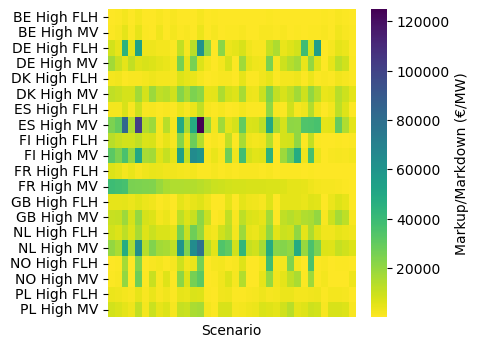

In [ ]:
###Figure 8b
plt.figure(figsize=(4, 4))
ax=sns.heatmap(df_plot_pivot,cmap="viridis_r",cbar_kws={'label': 'Markup/Markdown (€/MW)'},annot=False, xticklabels=False)
ax.set(xlabel='Scenario') 
ax.set(ylabel='') 
plt.yticks(rotation=0)
plt.show()

In [ ]:
#load strike prices stored in script "1_ExAnte"
file = open("C:/Users/silke/WORK/3_Model/scripts/scripts/CfDs_2/pickle/strikeprice_ALL",'rb')
df_sp= pickle.load(file)

In [ ]:
#calculate CfD payments
df_sp["node"]=df_sp["node"].map(lambda x: str(x)[:2])
df_payments=df_sp.merge(df_p,on=["node","unit"],how='left')
df_payments["subsidy"]=0

df_payments=df_payments[["scen","rev","unit","node","lcoe","v_i","v","gen","capacity","r_i","r","Profile","type","ann_cost_mw","strikeprice"]]

df_2way=df_payments[df_payments["type"]=="2way CfD"]
df_2way["subsidy"]=(df_2way["strikeprice"]-df_2way["v"])*df_2way["gen"]

df_fin=df_payments[df_payments["type"]=="Financial CfD"]
df_fin["subsidy"]=(df_fin["strikeprice"]-df_fin["r"])*df_fin["capacity"]

df_basic=df_payments[df_payments["type"]=="Basic CfD"]
df_basic["subsidy"]=df_basic["strikeprice"]*df_basic["gen"]-df_basic["rev"]

df_none=df_payments[df_payments["type"]=="Basic CfD"]
df_none["type"]="No CfD"
df_none["subsidy"]=0

In [25]:
#rate of cost recovery and cfd payments relative to market revenues
df_payments=pd.concat([df_basic,df_2way,df_fin,df_none])
df_payments["ann_cost"]=df_payments["ann_cost_mw"]*df_payments["capacity"]
df_payments["cost_rec"]=(df_payments["rev"]+df_payments["subsidy"])/df_payments["ann_cost"]*100

In [ ]:
#coefficient of variation of cost recovery
df_payments["profits"]=(df_payments["rev"]+df_payments["subsidy"])/df_payments["ann_cost"]

df_sd=df_payments[["unit","node","type","scen","profits"]]
df_sd=df_sd.groupby(["unit","node","type"]).std(numeric_only=True).reset_index().rename(columns={"profits":"profit_sd"}).round(3)
df_mean=df_payments[["unit","node","type","scen","profits"]]

df_mean=df_mean.groupby(["unit","node","type"]).mean(numeric_only=True).reset_index().rename(columns={"profits":"profit_mean"}).round(3)
df_mean=df_mean.merge(df_sd,on=["unit","type","node"])
df_mean["vol"]=(df_mean["profit_sd"]/df_mean["profit_mean"]).round(3)

In [ ]:
#rename
df_plot=df_mean
df_plot["unit"] = df_plot["unit"].str.replace(r'\bWind Onshore New 2\b', 'High MV', regex=True)
df_plot["unit"] = df_plot["unit"].str.replace(r'\bWind Onshore New 1\b', 'High FLH', regex=True)
df_plot = df_plot.pivot(index="unit", columns="type", values="vol")

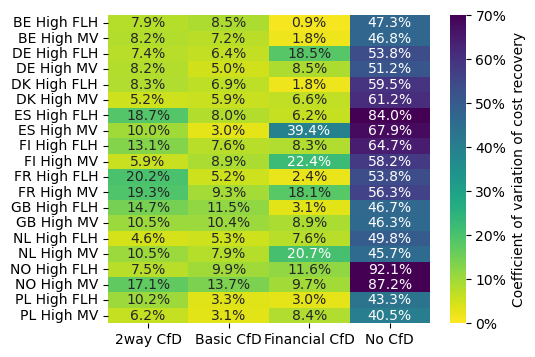

In [ ]:
###Figure 8a
plt.figure(figsize=(5.2, 4))
ax=sns.heatmap(df_plot,vmin=0, vmax=0.7,cmap="viridis_r",cbar_kws={'label': 'Coefficient of variation of cost recovery',},annot=True,fmt=".1%")
ax.set(xlabel='') 
ax.set(ylabel='') 
colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7])  
colorbar.set_ticklabels(['0%', '10%', '20%', '30%', '40%', '50%', '60%', '70%'])
plt.show()

In [ ]:
#load results from your path
res=BackboneScenarioAnalysis("C:/Users/silke/WORK/3_Model/Results/20251410_CfD_Paper_2")

In [ ]:
#Consumer Costs
df_con=pd.DataFrame()
for s, r in zip(res.scenarios, res.bb_results):     
    #electricity prices    
    r_gnConsumption = r.r_gnConsumption()
    #nodes=["ES elec","FR elec","DK elec"]
    r_gnConsumption=r_gnConsumption[r_gnConsumption['grid'].apply(lambda x: 1 if any(i in x for i in ["elec"]) else 0)==1]
    r_gnConsumption["scen"]=str(s)
    df_con=pd.concat([df_con,r_gnConsumption])

In [ ]:
#merge data and define components
df_price=df_mo[["price","node","scen","t"]]
df_costs=df_con.merge(df_price,on=["node","scen","t"])
df_costs["costs"]=df_costs["price"]*df_costs["Val"]*-1
df_costs["node"]=df_costs["node"].map(lambda x: str(x)[:2])

df_costs=df_costs[["node","scen","Val","costs"]]
df_costs=df_costs.groupby(["node","scen"]).sum().reset_index()

df_subsidycosts=df_payments.groupby(["node","scen","type"]).sum().reset_index()

df_costs=df_subsidycosts.merge(df_costs,on=["node","scen"],how="left")

df_costs["Electricity Price"]=df_costs["costs"]/df_costs["Val"]*-1
df_costs["Levy"]=df_costs["subsidy"]/df_costs["Val"]*-1
df_costs["Total Consumer Price"]=df_costs["Electricity Price"]+df_costs["Levy"]

In [ ]:
#coefficient of variation of consumer costs
df_sd=df_costs[["node","type","scen","Total Consumer Price"]]
df_sd=df_sd.groupby(["node","type"]).std(numeric_only=True).reset_index().rename(columns={"Total Consumer Price":"cp_sd"})

df_mean=df_costs[["node","type","scen","Total Consumer Price"]]
df_mean=df_mean.groupby(["node","type"]).mean(numeric_only=True).reset_index().rename(columns={"Total Consumer Price":"cp_mean"})
df_mean=df_mean.merge(df_sd,on=["type","node"])
df_mean["vol"]=df_mean["cp_sd"]/df_mean["cp_mean"]
#df_mean=df_mean.pivot(index="type",columns="node",values="vol")

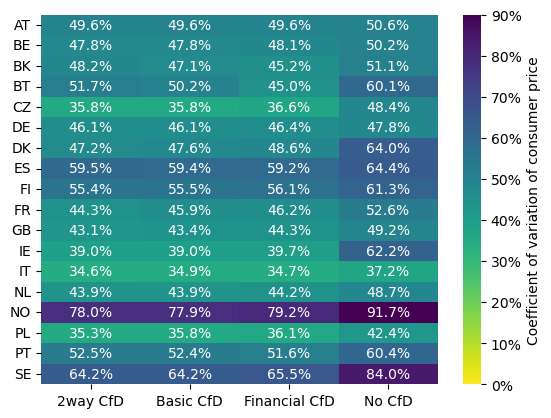

In [ ]:
###Figure 10
df_plot=df_mean

df_plot = df_plot.pivot(index="node", columns="type", values="vol")
ax=sns.heatmap(df_plot,vmin=0, vmax=df_plot.values.max().round(1),cmap="viridis_r",cbar_kws={'label': 'Coefficient of variation of consumer price'},annot=True,fmt=".1%")
ax.set(xlabel='') 
ax.set(ylabel='') 
ax.tick_params(axis='y', labelrotation=0)
colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7,0.8, 0.9])  # positions
colorbar.set_ticklabels(['0%', '10%', '20%', '30%', '40%', '50%', '60%', '70%','80%', '90%'])
plt.show()